# Assignment 03: Flow Matching

In this assignment you implement flow matching and train it on the same data as in Assignments 01 and 02, a small subset of MNIST: the digits 0, 1, 2, 3, 4 as gray images of 32 x 32 pixels, with 100 training images and 1000 test images per digit. The images come without labels.

You train a velocity field `v(x, t)` that moves noise `x ~ N(0, I)` at `t = 0` to the training images at `t = 1`. New images are generated by moving noise along the velocity field.

**Do not modify this notebook.** It runs the code that you write, measures the trained model, and saves the results.

You write the files in the `code` folder:

| File | What you write |
|---|---|
| `code/myinfo.py` | your name and student ID |
| `code/mymodel.py` | the velocity field |
| `code/myoptim.py` | batch size, number of epochs, optimizer |
| `code/mytrain.py` | path from noise to data, loss function, training for one epoch |
| `code/mysample.py` | number of steps, Euler method, generation of new images |

Every part to write is marked with `TODO`, and the docstring of each function specifies its inputs and outputs. Keep these interfaces unchanged.

The files in the `util` folder are provided; do not modify them:

| File | What it provides |
|---|---|
| `util/data.py` | `get_dataset("train")` and `get_dataset("test")`: the training and the test images |
| `util/result.py` | `evaluate`: FID of the trained model on the test images; `save`: writes it to a file |

The data files in the `data` folder are created by `util/prepare_data_mnist.py`.

Run all the cells from top to bottom (*Restart* and *Run All*). The notebook saves:

| File | Content |
|---|---|
| `train/loss.png`, `train/model.pt` | training curve, trained velocity field |
| `sample/sample.png` | images generated by the trained model |
| `result/trajectory.png` | images along the paths from noise to data |
| `result/steps.png` | images generated with different numbers of steps |
| `result/result_<student ID>_<name>.csv` | FID |

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

# The notebook is in the project folder, next to the folders code, util, data
ROOT = Path.cwd()
assert (ROOT / "code").is_dir() and (ROOT / "util").is_dir(), (
    f"run this notebook from the project folder, which contains code and util (now in {ROOT})")

# Make the files of code (yours) and util (provided) importable
for folder in ("code", "util"):
    if str(ROOT / folder) not in sys.path:
        sys.path.insert(0, str(ROOT / folder))

# Folders for the files saved by the notebook
TRAIN_DIR, SAMPLE_DIR, RESULT_DIR = ROOT / "train", ROOT / "sample", ROOT / "result"
for folder in (TRAIN_DIR, SAMPLE_DIR, RESULT_DIR):
    folder.mkdir(exist_ok=True)

SEED = 0
torch.manual_seed(SEED)

# GPU of NVIDIA (cuda) or of an Apple silicon Mac (mps) if there is one, else the CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"torch   : {torch.__version__}")
print(f"device  : {device}")
print(f"project : {ROOT}")

torch   : 2.15.0+cu132
device  : cuda
project : /nas2/users/hong/class/neural-network/2026/project/project-03


In [2]:
# Helper functions and colors for the figures

BLUE = "#2a78d6"                                         # data
GRAY, GRID, INK = "#c3c2b7", "#e1e0d9", "#52514e"        # context, grid lines, text


def to_grid(images, num_cols):
    # Tile images of shape (N, 1, H, W) into one image with num_cols columns.
    images = images.detach().cpu().float()
    height, width = images.shape[-2:]
    images = images.reshape(-1, num_cols, height, width)
    return images.permute(0, 2, 1, 3).reshape(-1, num_cols * width)


def show_grid(ax, images, num_cols, title, row_names=None):
    # Show the images as a grid; row_names gives one name per row of the grid.
    ax.imshow(to_grid(images, num_cols), cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    if row_names is None:
        ax.axis("off")
    else:
        height = images.shape[-2]
        ax.set_xticks([])
        ax.set_yticks([height * (row + 0.5) - 0.5 for row in range(len(row_names))], row_names)
        ax.tick_params(length=0, labelcolor=INK)
        ax.spines[:].set_visible(False)


def style_axes(ax):
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRAY)
    ax.tick_params(color=GRAY, labelcolor=INK)


def save_figure(fig, path):
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

## 1. Student information

`code/myinfo.py`

In [3]:
from myinfo import get_info

info = get_info()
assert info["name"] and info["student_id"], "fill in your name and student ID in code/myinfo.py"

print(f"name       : {info['name']}")
print(f"student ID : {info['student_id']}")

name       : Gildong Hong
student ID : 20260000


## 2. Data

`util/data.py` (provided) gives the training and the test images. The training images are read in mini-batches with the batch size from `code/myoptim.py`: every batch of `train_loader` is a tensor of images of shape `(B, 1, 32, 32)` with values in `[0, 1]`. There are no labels.

In [4]:
from data import get_dataset
from myoptim import BATCH_SIZE, NUM_EPOCHS

train_dataset = get_dataset("train")
test_dataset = get_dataset("test")

# the training images are reshuffled at every epoch
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

image_shape = tuple(train_dataset.images.shape[1:])

print(f"training images : {len(train_dataset)} ({len(train_loader)} batches of {BATCH_SIZE})")
print(f"test images     : {len(test_dataset)}")
print(f"image           : shape {image_shape}, values in "
      f"[{train_dataset.images.min().item():.0f}, {train_dataset.images.max().item():.0f}]")

training images : 500 (8 batches of 64)
test images     : 5000
image           : shape (1, 32, 32), values in [0, 1]


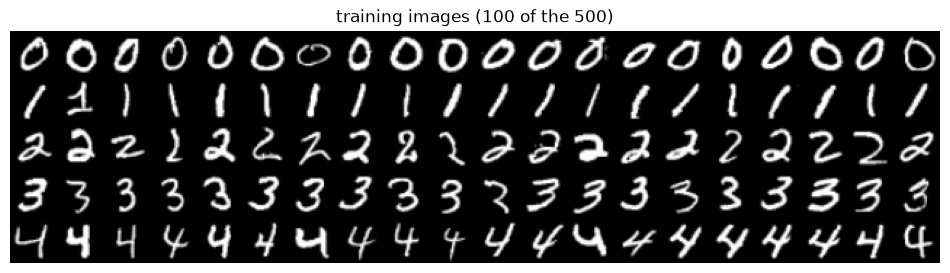

In [5]:
# One training image out of 5
examples = train_dataset.images[::5]

fig, ax = plt.subplots(figsize=(12, 3.2))
show_grid(ax, examples, 20, f"training images ({len(examples)} of the {len(train_dataset)})")
plt.show()

## 3. Model

`code/mymodel.py`

The velocity field gives the velocities `v = model(x, t)` of shape `(B, 1, 32, 32)` for images `x` of shape `(B, 1, 32, 32)` at the times `t` of shape `(B,)`.

In [6]:
from mymodel import VelocityField

model = VelocityField().to(device)
num_parameters = sum(p.numel() for p in model.parameters())

print(model)
print(f"number of parameters : {num_parameters:,}")

VelocityField(
  (encoder1): Sequential(
    (0): Conv2d(2, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
  )
  (encoder2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
  )
  (encoder3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
  )
  (decoder3): Sequential(
    (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
  )
  (decoder2): Sequential(
    (0): ConvTranspose2d(256, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
  )
  (decoder1): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
)
number of parameters : 1,446,529


In [7]:
# Check the interface of the model on a few images

x = torch.randn(8, *image_shape, device=device)
t = torch.rand(8, device=device)

with torch.no_grad():
    v = model(x, t)

assert v.shape == x.shape, f"model: output has shape {tuple(v.shape)}, expected {tuple(x.shape)}"

print("the velocity field has the expected interface")

the velocity field has the expected interface


## 4. Optimizer

`code/myoptim.py`

In [8]:
from myoptim import get_optimizer

optimizer = get_optimizer(model)

print(f"batch size       : {BATCH_SIZE}")
print(f"number of epochs : {NUM_EPOCHS}")
print(optimizer)

batch size       : 64
number of epochs : 1000
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## 5. Training

`code/mytrain.py`

The path from noise to data and the loss function are first checked on cases whose values are known. `x0` is the noise, `x1` the data, and `D` the number of pixels of an image.

| Function | Case | Expected value |
|---|---|---|
| `interpolate` | `t = 0` | `x0` |
| `interpolate` | `t = 0.25` | `0.75 x0 + 0.25 x1` |
| `interpolate` | `t = 1` | `x1` |
| `loss_function` | `v = x1 - x0`, the target | 0 |
| `loss_function` | `v = 0`, `x0 = 0`, `x1 = 1` in every pixel | `D` |
| `loss_function` | `v = 1`, `x0 = 1`, `x1 = 0` in every pixel | `4 D` |

In [9]:
from mytrain import interpolate, loss_function

shape = (3, *image_shape)
D = train_dataset.images[0].numel()          # number of pixels of an image
x0, x1 = torch.randn(shape, device=device), torch.randn(shape, device=device)
t = torch.tensor([0.0, 0.25, 1.0], device=device)

x_t = interpolate(x0, x1, t)

assert x_t.shape == shape, f"interpolate: output has shape {tuple(x_t.shape)}, expected {shape}"
assert torch.allclose(x_t[0], x0[0], atol=1e-5), "interpolate: x_t must be x0 at t = 0"
assert torch.allclose(x_t[1], 0.75 * x0[1] + 0.25 * x1[1], atol=1e-5), "interpolate: x_t must be 0.75 x0 + 0.25 x1 at t = 0.25"
assert torch.allclose(x_t[2], x1[2], atol=1e-5), "interpolate: x_t must be x1 at t = 1"
print("interpolate gives the expected points")

zeros, ones = torch.zeros(shape, device=device), torch.ones(shape, device=device)

checks = [
    ("loss_function, v = x1 - x0", loss_function(x1 - x0, x0, x1), 0),
    ("loss_function, v = 0, x0 = 0, x1 = 1", loss_function(zeros, zeros, ones), D),
    ("loss_function, v = 1, x0 = 1, x1 = 0", loss_function(ones, ones, zeros), 4 * D),
]

for name, value, expected in checks:
    assert torch.is_tensor(value) and value.shape == (), f"{name}: the loss must be a scalar tensor"
    assert abs(value.item() - expected) < 1e-2, f"{name}: got {value.item():.4f}, expected {expected:.4f}"
    print(f"{name:38s}: {value.item():10.4f}")

print("the loss function gives the expected values")

interpolate gives the expected points
loss_function, v = x1 - x0            :     0.0000
loss_function, v = 0, x0 = 0, x1 = 1  :  1024.0000
loss_function, v = 1, x0 = 1, x1 = 0  :  4096.0000
the loss function gives the expected values


The velocity field is trained for `NUM_EPOCHS` epochs.

In [10]:
from mytrain import train_one_epoch

history = []

for epoch in range(1, NUM_EPOCHS + 1):
    values = train_one_epoch(model, optimizer, train_loader, device)
    history.append(float(values["loss"]))

    if epoch == 1 or epoch == NUM_EPOCHS or epoch % max(1, NUM_EPOCHS // 20) == 0:
        print(f"epoch {epoch:5d}/{NUM_EPOCHS} | loss {values['loss']:7.3f}")

torch.save(model.state_dict(), TRAIN_DIR / "model.pt")

epoch     1/1000 | loss 1105.951


epoch    50/1000 | loss 176.334


epoch   100/1000 | loss 162.382


epoch   150/1000 | loss 136.671


epoch   200/1000 | loss 118.397


epoch   250/1000 | loss 120.733


... (11 outputs left out)

epoch   850/1000 | loss  94.240


epoch   900/1000 | loss  88.483


epoch   950/1000 | loss  88.014


epoch  1000/1000 | loss  93.031


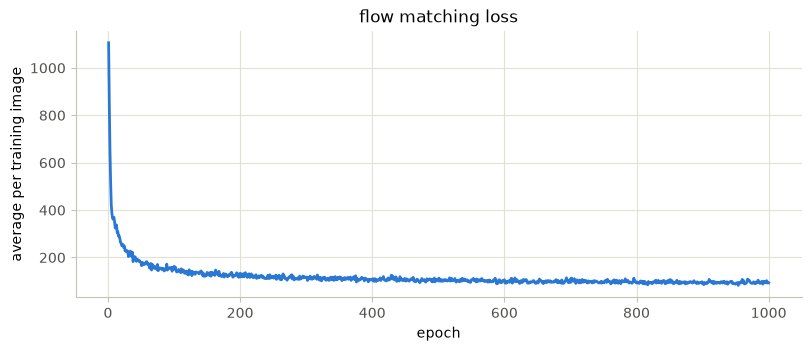

In [11]:
epochs = range(1, NUM_EPOCHS + 1)

fig, ax = plt.subplots(figsize=(8, 3.4), constrained_layout=True)
ax.plot(epochs, history, color=BLUE, linewidth=2)
ax.set_title("flow matching loss")
ax.set_xlabel("epoch")
ax.set_ylabel("average per training image")
style_axes(ax)
save_figure(fig, TRAIN_DIR / "loss.png")

## 6. Sampling

`code/mysample.py`

The Euler method is first checked on three velocity fields whose result is known. The images start from `x` at `t = 0` and are moved to `t = 1` in `N` steps.

| Velocity field | Images at `t = 1` |
|---|---|
| `v(x, t) = 1` in every pixel | `x + 1` |
| `v(x, t) = t` in every pixel | `x + (N - 1) / (2 N)` |
| `v(x, t) = x` | `x (1 + 1 / N)^N` |

In [12]:
from mysample import NUM_STEPS, integrate, sample


class Field(torch.nn.Module):
    # Velocity field given by a function of x, of shape (B, 1, 32, 32), and of t, reshaped to (B, 1, 1, 1).
    def __init__(self, function):
        super().__init__()
        self.function = function

    def forward(self, x, t):
        assert torch.is_tensor(t) and t.shape == (len(x),), "integrate: give the time to the model as a tensor of shape (B,)"
        return self.function(x, t.view(-1, 1, 1, 1))


N = 4
x = torch.randn(8, *image_shape, device=device)

path = integrate(Field(lambda x, t: torch.ones_like(x)), x, N)
moves = torch.arange(N + 1, device=device).view(-1, 1, 1, 1, 1) / N       # 0, 1/N, ..., 1
assert torch.is_tensor(path) and path.shape == (N + 1, *x.shape), f"integrate: the path must be a tensor of shape {(N + 1, *x.shape)}"
assert torch.allclose(path[0], x), "integrate: path[0] must be the input x"
assert torch.allclose(path, x + moves, atol=1e-5), "integrate, v = 1: x must move by 1 / num_steps at every step"

path = integrate(Field(lambda x, t: t.expand_as(x)), x, N)
assert torch.allclose(path[-1], x + (N - 1) / (2 * N), atol=1e-5), "integrate, v = t: the times of the steps must be 0, 1 / num_steps, ..., (num_steps - 1) / num_steps"

path = integrate(Field(lambda x, t: x), x, N)
assert torch.allclose(path[-1], x * (1 + 1 / N) ** N, atol=1e-4), "integrate, v = x: the velocity of a step must be taken at the current x"

path = integrate(model, x, N)
assert not path.requires_grad, "integrate: do not track gradients (torch.no_grad)"

print("the Euler method gives the expected images")

the Euler method gives the expected images


New images are generated in `NUM_STEPS` steps.

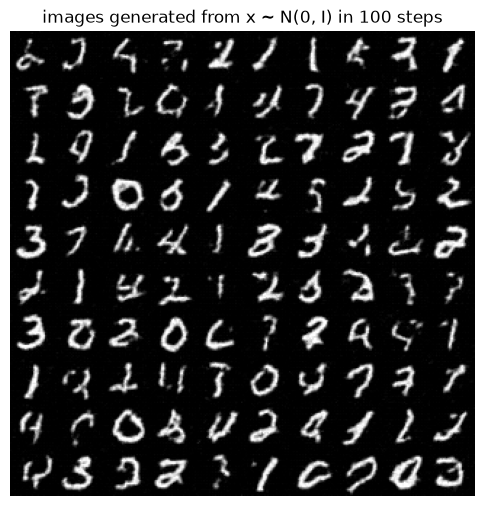

In [13]:
samples = sample(model, 100, NUM_STEPS, device)

assert samples.shape == (100, *image_shape), f"sample: output has shape {tuple(samples.shape)}"
assert 0 <= samples.min() and samples.max() <= 1, "sample: the values must be in [0, 1]"

fig, ax = plt.subplots(figsize=(6, 6.3))
show_grid(ax, samples, 10, f"images generated from x ~ N(0, I) in {NUM_STEPS} steps")
save_figure(fig, SAMPLE_DIR / "sample.png")

## 7. From noise to data

Images along the paths: each row follows one image from the noise at `t = 0` (left) to `t = 1` (right) in 19 steps. The values are shown from 0 (black) to 1 (white), and the values outside this range as black or white.

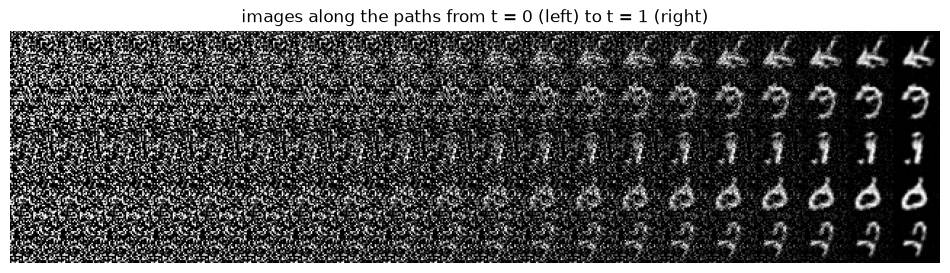

In [14]:
num_rows, num_cols = 5, 20

x = torch.randn(num_rows, *image_shape, device=device)
path = integrate(model, x, num_cols - 1)            # shape (num_cols, num_rows, 1, 32, 32)

images = path.transpose(0, 1).reshape(num_rows * num_cols, *image_shape)

fig, ax = plt.subplots(figsize=(12, 3.2))
show_grid(ax, images, num_cols, "images along the paths from t = 0 (left) to t = 1 (right)")
save_figure(fig, RESULT_DIR / "trajectory.png")

Images generated from the same 20 noises with different numbers of steps: one row per number of steps, one column per noise.

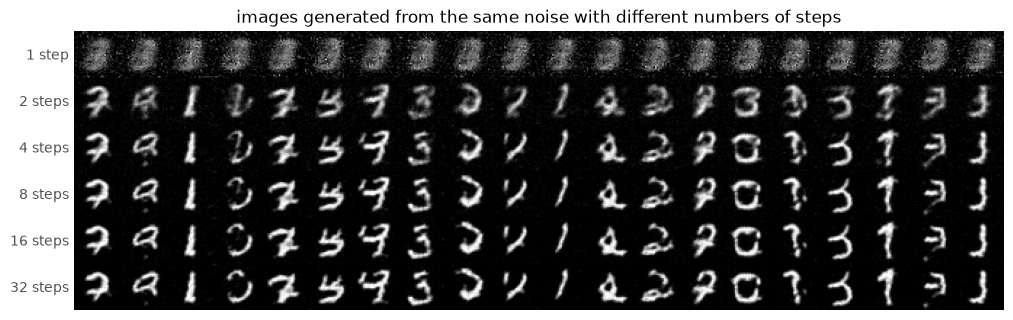

In [15]:
STEPS = (1, 2, 4, 8, 16, 32)

x = torch.randn(20, *image_shape, device=device)

images = torch.cat([integrate(model, x, num_steps)[-1].cpu() for num_steps in STEPS])

fig, ax = plt.subplots(figsize=(12, 0.62 * len(STEPS) + 0.5))
show_grid(ax, images, len(x), "images generated from the same noise with different numbers of steps",
          row_names=[f"{num_steps} step" + "s" * (num_steps > 1) for num_steps in STEPS])
save_figure(fig, RESULT_DIR / "steps.png")

## 8. Results

`util/result.py` (provided) measures the trained model with the 5,000 test images. Lower is better.

- **FID**: distance between the distribution of 5,000 images generated by the model in `NUM_STEPS` steps and the distribution of the test images.

The first run downloads the network used by the FID (about 100 MB). The cell takes seconds with a GPU, but can take more than 10 minutes with a CPU.

In [16]:
from result import evaluate, save

result = evaluate(model, integrate, NUM_STEPS)
result_file = save(result, info)

print(f"name                 : {info['name']}")
print(f"student ID           : {info['student_id']}")
print(f"batch size           : {BATCH_SIZE}")
print(f"number of epochs     : {NUM_EPOCHS}")
print(f"number of steps      : {NUM_STEPS}")
print(f"number of parameters : {num_parameters:,}")
print()
print(f"FID                  : {result['fid']:.2f}")
print()
print(f"saved {result_file}")

/home/hong/class/neural-network/2026/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


name                 : Gildong Hong
student ID           : 20260000
batch size           : 64
number of epochs     : 1000
number of steps      : 100
number of parameters : 1,446,529

FID                  : 40.89

saved /nas2/users/hong/class/neural-network/2026/project/project-03/result/result_20260000_Gildong_Hong.csv
